

**Atualização bibliográfica de 29/10/2026.** As referências adicionais foram confrontadas com o texto integral fornecido. Elas foram incorporadas onde sustentam diretamente a motivação operacional, a avaliação temporal ou os limites de transferência. Não houve alteração de resultados nem novo treinamento nesta revisão; quando a nova literatura sugere procedimentos não executados, eles são identificados apenas como limites ou possibilidades de validação futura.


# Notebook 3A.01 — Aprimoramento da modelagem preditiva de CO₂

## Enriquecimento da representação temporal do processo

Este notebook dá continuidade ao **Notebook 3A — Modelagem preditiva das emissões horárias de CO₂**.

O experimento anterior comparou:

**Cenário A — carga instantânea**

`CO₂(t) = f(P(t))`

**Cenário B — carga + trajetória operacional básica**

`CO₂(t) = f(P(t), P(t−1), ΔP, |ΔP|, média 3h, OT(t−1), horas desde startup)`

O Cenário B apresentou melhor desempenho global que o Cenário A, indicando que informações sobre o processo operacional contribuem para a estimação horária de CO₂.

Entretanto, o diagnóstico revelou pontos importantes:

1. a melhora não foi uniforme entre os regimes operacionais;
2. o ganho foi particularmente elevado nas primeiras horas após startups;
3. durante rampas intensas, o Cenário B apresentou desempenho inferior ao Cenário A;
4. permaneceu uma tendência de subestimação das emissões no período de teste.

## Hipótese desta etapa

Uma possível limitação do Cenário B é que sua representação da trajetória operacional ainda é curta.

O modelo conhece a carga atual, apenas um lag explícito e algumas variáveis agregadas, mas não descreve detalhadamente a sequência recente de mudanças da unidade.

Assim, este notebook testa a hipótese:

> **Uma representação temporal mais completa da trajetória operacional melhora a estimação horária de CO₂ em relação ao Cenário B?**

## Estratégia de aprimoramento

Será criado um novo:

### Cenário C — trajetória temporal enriquecida

Serão mantidas as sete variáveis do Cenário B e acrescentadas informações sobre:

- carga de 2, 3 e 6 horas atrás;
- comportamento das rampas nas horas anteriores;
- aceleração ou desaceleração da carga;
- média móvel em janela maior;
- variabilidade recente da carga;
- amplitude recente de operação;
- mudança líquida de carga em 3 e 6 horas;
- proporção recente de horas em operação;
- identificação das primeiras horas após startup;
- intensidade e direção das rampas.

## Controle experimental

Para isolar o efeito da representação dos dados, serão mantidos:

- mesma arquitetura MLP: `64 → 32 → 1`;
- mesma função de perda MSE;
- mesmo otimizador Adam;
- mesmo learning rate;
- mesmo batch size;
- mesmo EarlyStopping;
- mesma divisão temporal;
- mesma normalização Min-Max ajustada somente no treino.

Portanto, a principal alteração entre os Cenários B e C será a **informação fornecida ao modelo**.

## Avaliação

Ao final serão comparados:

- MAE;
- RMSE;
- R²;
- viés médio;
- desempenho nas primeiras 6 horas após startup;
- desempenho em rampas intensas;
- percentual de horas em que o Cenário C supera o Cenário B.

Também será realizada uma análise de possíveis diferenças de distribuição entre treino, validação e teste.

## Observação metodológica

Novembro e dezembro permanecem como período de comparação para manter compatibilidade com o Notebook 3A.

Entretanto, como os resultados desse período já foram observados durante o diagnóstico anterior, ele deixa de representar um teste completamente cego para decisões futuras de desenvolvimento.

Uma avaliação final de generalização deverá, idealmente, utilizar dados ainda não observados.

## Fundamentação metodológica do Notebook 3A.01

Este experimento pertence ao campo de **aprendizado supervisionado para regressão (*supervised regression*)**. O estimador é uma **Multilayer Perceptron (MLP)**, isto é, uma **rede neural artificial do tipo *feedforward***, com camadas densas e saída contínua para estimar a massa horária de CO₂ a partir das condições operacionais da unidade. A MLP não é uma rede recorrente (RNN/LSTM): a memória operacional entra por **variáveis construídas explicitamente a partir da série temporal**.

O procedimento central deste notebook é a **engenharia de variáveis temporais (*temporal feature engineering*)**. O Cenário C acrescenta variáveis de histórico, janelas móveis e estados operacionais ao Cenário B. O contraste B × C constitui uma **comparação controlada dos conjuntos de variáveis (*controlled feature-set comparison*)**, com lógica de ablação incremental: busca-se verificar se a representação temporal mais rica é útil mantendo, tanto quanto possível, a mesma família de modelo e as mesmas regras de treinamento. Como B foi produzido no experimento anterior, a interpretação deve considerar a compatibilidade efetiva das amostras utilizadas, e não presumir pareamento perfeito de todas as observações.

**Escopo preditivo:** como há variáveis operacionais referentes à própria hora `t`, incluindo `P(t)`, o problema é de **estimação contemporânea da emissão horária**, não necessariamente de previsão antecipada de uma hora futura. Para realizar previsão com antecedência seria preciso restringir as entradas às informações de fato disponíveis no instante da previsão.

A formulação do experimento exige cuidados com a ordenação temporal, as variáveis defasadas e a separação cronológica dos conjuntos de treinamento, validação e teste.

## Fundamentação, fontes e decisões do protocolo

As notas metodológicas vinculam as técnicas empregadas às respectivas publicações ou documentações oficiais. As referências completas aparecem ao final deste notebook. As rotinas de leitura, persistência, verificação de integridade e organização dos resultados são implementações do projeto.

**Escolhas do estudo.** A seleção de atributos, os comprimentos das defasagens e das janelas, a arquitetura preservada e os recortes operacionais constituem escolhas do estudo. A adição de atributos não comprova melhora universal, causalidade ou independência entre entradas.

**Atualização documental de 24/10/2026.** Foram acrescentadas explicações, citações e referências. As instruções executáveis e as saídas armazenadas foram preservadas. Esta revisão não corresponde a uma nova execução dos experimentos. A rastreabilidade da verificação computacional permanece nos registros de reprodução.

O [guia de fundamentação metodológica](../docs/fundamentacao_metodologica.md) relaciona as fontes, seu alcance e os controles adotados ao longo dos notebooks.


In [20]:
# ============================================================
# CÉLULA 1: CONFIGURAÇÃO DO AMBIENTE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preparar o ambiente do Notebook 3A.01.
#
# Nesta etapa:
#
#   1. importamos as bibliotecas utilizadas;
#   2. configuramos a reprodutibilidade;
#   3. montamos o Google Drive;
#   4. definimos os diretórios do projeto;
#   5. localizamos a série horária completa;
#   6. localizamos os resultados produzidos pelo Notebook 3A.
#
# Diferentemente do Notebook 3A, este notebook precisa acessar
# também a série horária completa, inclusive períodos OFF.
#
# Isso é necessário porque as novas features de trajetória
# utilizam informações das horas cronologicamente anteriores.
# ============================================================


# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from IPython.display import display, Markdown


# ============================================================
# 2. CONFIGURAÇÕES GERAIS
# ============================================================

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# Semente fixa
#
# A semente reduz diferenças aleatórias entre execuções,
# principalmente na inicialização dos pesos da rede neural.
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ------------------------------------------------------------
# Solicita operações determinísticas ao TensorFlow quando
# disponíveis no ambiente atual.
#
# O try/except evita interromper o notebook caso o recurso
# não esteja disponível no runtime utilizado.
# ------------------------------------------------------------

try:

    tf.config.experimental.enable_op_determinism()

except Exception:

    pass


# ============================================================
# 3. MONTAR O GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")


# ============================================================
# 4. DIRETÓRIO PRINCIPAL DO PROJETO
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/co2-cems-thermal-modeling"
)


# ------------------------------------------------------------
# Dados intermediários.
#
# Aqui está a série horária completa produzida anteriormente,
# antes da seleção exclusiva das horas ON para modelagem.
# ------------------------------------------------------------

DATA_INTERIM = (
    ROOT
    /
    "data"
    /
    "interim"
)


# ------------------------------------------------------------
# Diretório com informações persistentes do pipeline.
# ------------------------------------------------------------

PIPELINE_DIR = (
    ROOT
    /
    "pipeline"
)


# ============================================================
# 5. DIRETÓRIOS DE SAÍDA
# ============================================================

OUTPUT = (
    ROOT
    /
    "outputs"
)

REPORTS = (
    OUTPUT
    /
    "reports"
)

FIGURES = (
    OUTPUT
    /
    "figures"
)

TABLES = (
    OUTPUT
    /
    "tables"
)

MODELS = (
    OUTPUT
    /
    "models"
)


# ------------------------------------------------------------
# Cria as pastas caso ainda não existam.
# ------------------------------------------------------------

for folder in [
    REPORTS,
    FIGURES,
    TABLES,
    MODELS
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 6. ARQUIVOS DE ENTRADA
# ============================================================


# Identificação da unidade selecionada no Notebook 1.

CONFIG_PATH = (
    PIPELINE_DIR
    /
    "selected_unit.json"
)


# Série horária completa após feature engineering do Notebook 2.
#
# É utilizada para construir novos lags e janelas temporais.

FULL_DATA_PATH = (
    DATA_INTERIM
    /
    "step05_feature_engineering.parquet"
)


# ============================================================
# 7. RESULTADOS DO NOTEBOOK 3A
# ============================================================
#
# Estes arquivos permitem comparar diretamente o novo Cenário C
# com os Cenários A e B já executados.
# ============================================================

BASELINE_RESULTS_PATH = (
    TABLES
    /
    "03A_comparacao_modelos.csv"
)

BASELINE_CONTEXT_PATH = (
    TABLES
    /
    "03A_comparacao_contextos.csv"
)

BASELINE_PREDICTIONS_PATH = (
    TABLES
    /
    "03A_previsoes_teste.csv"
)


# ============================================================
# 8. CONFIRMAÇÃO DO AMBIENTE
# ============================================================

print("=" * 72)
print("NOTEBOOK 3A.01: APRIMORAMENTO DA MODELAGEM PREDITIVA")
print("=" * 72)

print(
    "\nDiretório do projeto:"
)

print(
    ROOT
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NOTEBOOK 3A.01: APRIMORAMENTO DA MODELAGEM PREDITIVA

Diretório do projeto:
/content/drive/MyDrive/co2-cems-thermal-modeling


In [21]:
# ============================================================
# CÉLULA 2: CARREGAMENTO DOS DADOS E DO BASELINE 3A
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Carregar:
#
#   1. a unidade selecionada;
#   2. a série horária completa;
#   3. as métricas do Notebook 3A;
#   4. os resultados por contexto do Notebook 3A;
#   5. as previsões hora a hora do Notebook 3A.
#
# Os resultados antigos NÃO são recalculados.
#
# Eles funcionam como referência fixa para comparação com o
# novo Cenário C.
# ============================================================


# ============================================================
# 1. VERIFICAR SE TODOS OS ARQUIVOS NECESSÁRIOS EXISTEM
# ============================================================

required_files = [

    CONFIG_PATH,

    FULL_DATA_PATH,

    BASELINE_RESULTS_PATH,

    BASELINE_CONTEXT_PATH,

    BASELINE_PREDICTIONS_PATH

]


for file_path in required_files:

    if not file_path.exists():

        raise FileNotFoundError(
            f"Arquivo necessário não encontrado: {file_path}"
        )


# ============================================================
# 2. CARREGAR IDENTIFICAÇÃO DA UNIDADE
# ============================================================

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:

    selected_unit = json.load(f)


# ============================================================
# 3. CARREGAR A SÉRIE HORÁRIA COMPLETA
# ============================================================
#
# Neste notebook não utilizamos inicialmente apenas as horas ON.
#
# A cronologia completa é necessária para que, por exemplo,
# P(t-6) realmente represente seis horas antes de P(t),
# inclusive se a unidade estivesse desligada nesse intervalo.
# ============================================================

df = pd.read_parquet(
    FULL_DATA_PATH
)


# ------------------------------------------------------------
# Garantir que timestamp seja tratado como variável temporal.
# ------------------------------------------------------------

df["timestamp"] = pd.to_datetime(
    df["timestamp"]
)


# ------------------------------------------------------------
# Garantir ordem cronológica antes da criação dos lags.
#
# shift() depende diretamente da ordem das linhas.
# ------------------------------------------------------------

df = (

    df

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 4. CARREGAR RESULTADOS DO NOTEBOOK 3A
# ============================================================


# Métricas globais dos Cenários A e B.

baseline_results = pd.read_csv(
    BASELINE_RESULTS_PATH
)


# Métricas por contexto operacional.

baseline_context = pd.read_csv(
    BASELINE_CONTEXT_PATH
)


# Previsões individuais das horas do teste.

baseline_predictions = pd.read_csv(
    BASELINE_PREDICTIONS_PATH
)


# ------------------------------------------------------------
# Converter também o timestamp das previsões antigas.
#
# Isso será necessário posteriormente para fazer merge entre
# as previsões do Cenário B e as novas previsões do Cenário C.
# ------------------------------------------------------------

baseline_predictions["timestamp"] = pd.to_datetime(
    baseline_predictions["timestamp"]
)


# ============================================================
# 5. CONFERÊNCIA DOS DADOS CARREGADOS
# ============================================================

print("=" * 72)
print("DADOS CARREGADOS")
print("=" * 72)


print(
    f"\nUnidade: "
    f"{selected_unit['facility_name']} "
    f"Unit {selected_unit['unit_id']}"
)


print(
    "Facility ID:",
    selected_unit["facility_id"]
)


print(
    "Ano:",
    selected_unit["year"]
)


print(
    "\nRegistros horários disponíveis:",
    f"{len(df):,}"
)


print(
    "Período:",
    df["timestamp"].min(),
    "→",
    df["timestamp"].max()
)


# ------------------------------------------------------------
# Mostrar as métricas do experimento anterior.
#
# Isso deixa explícito, desde o início do notebook, qual é o
# desempenho que o Cenário C precisará superar.
# ------------------------------------------------------------

print(
    "\nResultados do Notebook 3A:"
)

display(
    baseline_results.round(4)
)

DADOS CARREGADOS

Unidade: Iatan Unit 2
Facility ID: 6065
Ano: 2025

Registros horários disponíveis: 8,760
Período: 2025-01-01 00:00:00 → 2025-12-31 23:00:00

Resultados do Notebook 3A:


,cenario,n_features,MAE,RMSE,R2
0,A — carga instantânea,1,67.2508,70.9010,0.8779
1,B — carga + trajetória,7,61.6102,67.0401,0.8908


## 3. Construção do Cenário C

As novas features serão calculadas sobre a **série horária completa**, e não somente sobre as horas ON.

Essa decisão é importante porque a trajetória imediatamente anterior a um startup pode conter horas OFF.

Por exemplo, para uma observação no início da operação:

`P(t−6), ..., P(t−1), P(t)`

deve representar as seis horas cronologicamente anteriores, mesmo que algumas delas correspondam ao estado desligado.

Nenhuma variável baseada em CO₂ será utilizada como entrada do modelo.

Assim, permanece evitado o **target leakage**.

### Célula 4: engenharia de variáveis temporais (*temporal feature engineering*)

As operações `shift()` e `rolling()` correspondem a técnicas reconhecidas de análise e aprendizado com séries temporais:

| Técnica | Implementação neste notebook | Interpretação |
|---|---|---|
| **Lagged features** (*variáveis defasadas*) | `shift(2)`, `shift(3)` e `shift(6)` em `load_current_mw` | Representam `P(t−2)`, `P(t−3)` e `P(t−6)`; registram observações anteriores. |
| **Lagged ramp features** | `shift(1)` e `shift(2)` em `delta_load_1h` | Descrevem a sequência recente de mudanças de carga. |
| **Rolling-window features** (*estatísticas em janela móvel*) | `shift(1).rolling(...)` seguido de `mean()`, `std()`, `min()` ou `max()` | Resumem nível, dispersão e amplitude das cargas em uma janela de observações anteriores. |
| **Temporal state features** | `on_fraction_previous_6h`, `startup_phase_6h` | Representam histórico recente de operação e fase após partida. |
| **Derived temporal features** | diferenças líquidas, aceleração, rampas de subida e descida | Caracterizam a forma e a direção da trajetória operacional. |

**Prevenção de *look-ahead bias* e *temporal data leakage*.** Nas estatísticas cuja finalidade é representar **apenas o passado**, aplicar `shift(1)` **antes** de `rolling(...)` evita que a própria observação em `t` participe do cálculo. Por exemplo, `load_mean_previous_6h` considera até seis valores anteriores à hora de interesse, não a carga da própria hora `t`. Isso é uma medida de proteção contra o uso acidental de informações contemporâneas ou futuras em atributos destinados a descrever o histórico. A característica `load_current_mw`, por sua vez, usa deliberadamente a hora atual porque este experimento estima CO₂ da mesma hora.

**Condição de validade temporal:** `shift(n)` desloca `n` **linhas**, não necessariamente `n` horas de relógio. A interpretação como defasagem horária pressupõe que a série tenha frequência horária regular e esteja adequadamente ordenada, sem lacunas que comprometam essa correspondência. O presente complemento nomeia a técnica, mas não substitui uma verificação específica de continuidade temporal.

**Controle de vazamento do alvo:** as novas entradas representam variáveis operacionais, não medições observadas de CO₂. Essa decisão protege contra a inserção direta da variável-alvo nas entradas, mas não garante, por si só, ausência de todas as formas possíveis de vazamento de dados.

### Fontes e escolhas da engenharia temporal

Gu, Sward e Zhang (2023) fornecem uma referência diretamente relacionada ao uso de variáveis operacionais horárias e de rampa em modelos de emissões de unidades geradoras. Suri, de Chalendar e Azevedo (2025) reforçam a relevância de transientes, partidas e baixos níveis de utilização para o desempenho emissivo de plantas térmicas. As variáveis defasadas e as janelas retrospectivas do Cenário C aprofundam essa representação, mas seus comprimentos, estatísticas e limiares são decisões deste experimento, não prescrições das fontes.

O `shift(1)` antes das janelas móveis mantém a estatística estritamente retrospectiva. A carga da hora corrente permanece disponível ao estimador, portanto o experimento não é apresentado como previsão antecipada sem conhecimento de P(t).


In [22]:
# Referências metodológicas: (Gu; Sward; Zhang, 2023; Suri; de Chalendar; Azevedo, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
#
# FUNDAMENTAÇÃO METODOLÓGICA: TEMPORAL FEATURE ENGINEERING
# - shift(n): lagged features (variáveis defasadas).
# - shift(1).rolling(...): rolling-window features calculadas sobre o passado.
# - shift(1) antes da janela móvel: prevenção de look-ahead bias
#   nas variáveis definidas como histórico, evitando temporal data leakage.
# - P(t) é conhecido neste protocolo de estimação contemporânea.
# - shift(n) equivale a n horas somente em série temporal horária regular.
#
# CÉLULA 4: ENRIQUECIMENTO DA TRAJETÓRIA OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Criar uma representação temporal mais detalhada da operação.
#
# No Cenário B, a memória do processo era relativamente curta.
#
# O Cenário C procura representar:
#
#   1. posição passada da carga;
#   2. sequência recente das rampas;
#   3. aceleração ou desaceleração;
#   4. nível médio recente de operação;
#   5. variabilidade da carga;
#   6. amplitude recente;
#   7. mudança acumulada em algumas horas;
#   8. histórico recente ON/OFF;
#   9. presença em fase de startup;
#  10. sentido das rampas.
#
#
# CUIDADO METODOLÓGICO
# ------------------------------------------------------------
# Nenhuma feature utiliza CO₂ observado como entrada.
#
# Portanto, não introduzimos target leakage.
#
# As features utilizam apenas informações operacionais atuais
# ou passadas.
# ============================================================


# ============================================================
# 1. VARIÁVEL-ALVO
# ============================================================

TARGET = "CO2 Mass (short tons)"


# ============================================================
# 2. LAGS ADICIONAIS DE CARGA
# ============================================================
#
# shift(n) desloca a série em n linhas.
#
# Como a base está ordenada hora a hora:
#
# load_lag_2h = P(t-2)
# load_lag_3h = P(t-3)
# load_lag_6h = P(t-6)
#
# O objetivo é permitir que a rede conheça não apenas a carga
# atual e a hora anterior, mas uma pequena sequência histórica.
# ============================================================

df["load_lag_2h"] = (
    df["load_current_mw"]
    .shift(2)
)

df["load_lag_3h"] = (
    df["load_current_mw"]
    .shift(3)
)

df["load_lag_6h"] = (
    df["load_current_mw"]
    .shift(6)
)


# ============================================================
# 3. HISTÓRICO DAS RAMPAS
# ============================================================
#
# delta_load_1h representa:
#
#       ΔP(t) = P(t) - P(t-1)
#
# Aqui recuperamos também as variações que ocorreram antes:
#
#       ΔP(t-1)
#       ΔP(t-2)
#
# Isso permite diferenciar uma rampa isolada de uma sequência
# contínua de aumentos ou reduções de carga.
# ============================================================

df["delta_load_lag_1h"] = (
    df["delta_load_1h"]
    .shift(1)
)

df["delta_load_lag_2h"] = (
    df["delta_load_1h"]
    .shift(2)
)


# ============================================================
# 4. ACELERAÇÃO DA CARGA
# ============================================================
#
# Definição:
#
#       aceleração(t) = ΔP(t) - ΔP(t-1)
#
# Exemplo:
#
# hora anterior: +50 MW/h
# hora atual:    +150 MW/h
#
# aceleração = +100 MW/h
#
# Portanto, a feature informa se a velocidade de mudança da
# carga está aumentando ou diminuindo.
#
# Valores positivos não significam necessariamente que a carga
# está subindo. Significam que ΔP aumentou em relação à hora
# anterior.
# ============================================================

df["load_acceleration_1h"] = (

    df["delta_load_1h"]

    -

    df["delta_load_lag_1h"]

)


# ============================================================
# 5. MÉDIA DAS 6 HORAS ANTERIORES
# ============================================================
#
# O shift(1) é fundamental.
#
# Ele garante que a média utilize apenas:
#
#       t-1, t-2, ..., t-6
#
# e NÃO inclua a própria hora t.
#
# A variável descreve o nível operacional recente da unidade.
# ============================================================

df["load_mean_previous_6h"] = (

    df["load_current_mw"]

    .shift(1)

    .rolling(
        window=6,
        min_periods=1
    )

    .mean()

)


# ============================================================
# 6. VARIABILIDADE RECENTE DA CARGA
# ============================================================
#
# O desvio padrão mostra se a carga esteve:
#
#   estável    → desvio padrão baixo
#   oscilante  → desvio padrão alto
#
# São criadas duas escalas temporais:
#
#   últimas 3 horas
#   últimas 6 horas
#
# Novamente, shift(1) evita incluir a hora atual.
# ============================================================

df["load_std_previous_3h"] = (

    df["load_current_mw"]

    .shift(1)

    .rolling(
        window=3,
        min_periods=2
    )

    .std()

    .fillna(0)

)


df["load_std_previous_6h"] = (

    df["load_current_mw"]

    .shift(1)

    .rolling(
        window=6,
        min_periods=2
    )

    .std()

    .fillna(0)

)


# ============================================================
# 7. AMPLITUDE DA CARGA NAS 6 HORAS ANTERIORES
# ============================================================
#
# Primeiro criamos uma série correspondente à carga anterior.
#
# Depois calculamos:
#
#       máximo das últimas 6 h
#       mínimo das últimas 6 h
#
# Finalmente:
#
#       amplitude = máximo - mínimo
#
# Quanto maior a amplitude, mais variável foi a trajetória
# recente da unidade.
# ============================================================

previous_load = (
    df["load_current_mw"]
    .shift(1)
)


df["load_min_previous_6h"] = (

    previous_load

    .rolling(
        window=6,
        min_periods=1
    )

    .min()

)


df["load_max_previous_6h"] = (

    previous_load

    .rolling(
        window=6,
        min_periods=1
    )

    .max()

)


df["load_range_previous_6h"] = (

    df["load_max_previous_6h"]

    -

    df["load_min_previous_6h"]

)


# ============================================================
# 8. MUDANÇA LÍQUIDA DE CARGA
# ============================================================
#
# Estas features respondem:
#
# "Quanto a carga atual difere da carga de 3 ou 6 horas atrás?"
#
#
# Exemplos:
#
# load_net_change_3h =
#       P(t) - P(t-3)
#
# load_net_change_6h =
#       P(t) - P(t-6)
#
#
# Valores positivos indicam que a carga atual está acima da
# carga passada.
#
# Valores negativos indicam redução líquida.
# ============================================================

df["load_net_change_3h"] = (

    df["load_current_mw"]

    -

    df["load_lag_3h"]

)


df["load_net_change_6h"] = (

    df["load_current_mw"]

    -

    df["load_lag_6h"]

)


# ============================================================
# 9. HISTÓRICO RECENTE DE OPERAÇÃO
# ============================================================
#
# is_on é uma variável binária:
#
#       ON  = 1
#       OFF = 0
#
# A média das seis horas anteriores equivale à fração de horas
# em que a unidade esteve ligada.
#
#
# Exemplos:
#
# 1.00 → esteve ligada em todas as 6 horas anteriores.
#
# 0.50 → esteve ligada em aproximadamente metade delas.
#
# 0.00 → esteve desligada em todas.
#
#
# Isso permite diferenciar uma unidade em operação contínua de
# uma unidade que acabou de sair de um período OFF.
# ============================================================

df["on_fraction_previous_6h"] = (

    df["is_on"]

    .astype(float)

    .shift(1)

    .rolling(
        window=6,
        min_periods=1
    )

    .mean()

)


# ============================================================
# 10. IDENTIFICAÇÃO DA FASE INICIAL APÓS STARTUP
# ============================================================
#
# Feature binária:
#
#       1 → entre a 1ª e a 6ª hora após startup
#       0 → demais situações
#
# O Notebook 3A mostrou que esse contexto operacional possui
# comportamento preditivo particularmente relevante.
# ============================================================

df["startup_phase_6h"] = (

    (
        df["hours_since_startup"]
        >=
        1
    )

    &

    (
        df["hours_since_startup"]
        <=
        6
    )

).astype(int)


# ============================================================
# 11. SEPARAÇÃO DO SENTIDO DAS RAMPAS
# ============================================================
#
# delta_load_1h contém valores positivos e negativos.
#
# Aqui criamos duas variáveis diferentes:
#
# ramp_up_mw:
#       mantém apenas aumentos de carga.
#
# ramp_down_mw:
#       mantém apenas reduções de carga, convertidas para
#       magnitude positiva.
#
#
# Exemplo:
#
# ΔP = +100 → ramp_up = 100 | ramp_down = 0
#
# ΔP = -100 → ramp_up =   0 | ramp_down = 100
#
# Isso facilita para a rede distinguir os dois sentidos.
# ============================================================

df["ramp_up_mw"] = (

    df["delta_load_1h"]

    .clip(
        lower=0
    )

)


df["ramp_down_mw"] = (

    -df["delta_load_1h"]

    .clip(
        upper=0
    )

)


# ============================================================
# 12. LISTA DAS NOVAS FEATURES
# ============================================================

new_features = [

    "load_lag_2h",
    "load_lag_3h",
    "load_lag_6h",

    "delta_load_lag_1h",
    "delta_load_lag_2h",

    "load_acceleration_1h",

    "load_mean_previous_6h",

    "load_std_previous_3h",
    "load_std_previous_6h",

    "load_range_previous_6h",

    "load_net_change_3h",
    "load_net_change_6h",

    "on_fraction_previous_6h",

    "startup_phase_6h",

    "ramp_up_mw",
    "ramp_down_mw"

]


# ============================================================
# 13. AUDITORIA DAS NOVAS FEATURES
# ============================================================
#
# Lags naturalmente podem gerar valores ausentes nas primeiras
# observações da série.
#
# Esta tabela permite verificar quantos NaN foram produzidos
# antes da construção da base experimental.
# ============================================================

feature_audit = pd.DataFrame({

    "feature":
        new_features,

    "ausentes":

        [

            int(
                df[col]
                .isna()
                .sum()
            )

            for col in new_features

        ]

})


print("=" * 72)
print("NOVAS FEATURES TEMPORAIS CRIADAS")
print("=" * 72)


display(
    feature_audit
)

NOVAS FEATURES TEMPORAIS CRIADAS


,feature,ausentes
0,load_lag_2h,2
1,load_lag_3h,3
2,load_lag_6h,6
3,delta_load_lag_1h,2
4,delta_load_lag_2h,3
5,load_acceleration_1h,2
6,load_mean_previous_6h,1
7,load_std_previous_3h,0
8,load_std_previous_6h,0
9,load_range_previous_6h,1


In [23]:
# ============================================================
# CÉLULA 5: DEFINIÇÃO DOS CENÁRIOS B E C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Formalizar a comparação deste notebook.
#
#
# Cenário B:
# representação temporal básica utilizada no Notebook 3A.
#
# Cenário C:
# mantém TODAS as variáveis de B e acrescenta as novas
# informações temporais criadas na célula anterior.
#
#
# Isso é importante porque C representa uma extensão de B,
# permitindo avaliar o valor incremental das novas features.
# ============================================================


# ============================================================
# 1. FEATURES ORIGINAIS DO CENÁRIO B
# ============================================================

FEATURES_B = [

    "load_current_mw",

    "load_lag_1h",

    "delta_load_1h",

    "abs_delta_load_1h",

    "load_mean_previous_3h",

    "operating_time_lag_1h",

    "hours_since_startup"

]


# ============================================================
# 2. FEATURES DO NOVO CENÁRIO C
# ============================================================

FEATURES_C = FEATURES_B + [

    "load_lag_2h",
    "load_lag_3h",
    "load_lag_6h",

    "delta_load_lag_1h",
    "delta_load_lag_2h",

    "load_acceleration_1h",

    "load_mean_previous_6h",

    "load_std_previous_3h",
    "load_std_previous_6h",

    "load_range_previous_6h",

    "load_net_change_3h",
    "load_net_change_6h",

    "on_fraction_previous_6h",

    "startup_phase_6h",

    "ramp_up_mw",
    "ramp_down_mw"

]


# ============================================================
# 3. TABELA RESUMO
# ============================================================

scenario_table = pd.DataFrame({

    "cenario": [

        "B: trajetória básica",

        "C: trajetória enriquecida"

    ],

    "n_features": [

        len(FEATURES_B),

        len(FEATURES_C)

    ]

})


display(
    scenario_table
)


# ============================================================
# 4. CONFERÊNCIA
# ============================================================

print(
    "\nFeatures adicionais no Cenário C:",
    len(FEATURES_C) - len(FEATURES_B)
)


print(
    "Total de features no Cenário C:",
    len(FEATURES_C)
)

,cenario,n_features
0,B: trajetória básica,7
1,C: trajetória enriquecida,23



Features adicionais no Cenário C: 16
Total de features no Cenário C: 23


### Fundamentação da divisão temporal

A avaliação de modelos para séries temporais precisa considerar a ordem das observações e o procedimento de estimação do desempenho (Cerqueira; Torgo; Mozetič, 2020). Neste estudo, as datas das partições e o calendário das validações são decisões do protocolo. O teste permanece fora do ajuste de cada comparação, mas seu uso reiterado no desenvolvimento limita a independência da avaliação em relação às decisões da pesquisa (Cawley; Talbot, 2010). A divisão cronológica, isoladamente, não elimina esse limite.


In [24]:
# Referências metodológicas: (Cerqueira; Torgo; Mozetič, 2020; Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
#
# FUNDAMENTAÇÃO METODOLÓGICA: TEMPORAL HOLDOUT
# Ordem cronológica fixa: passado para treino, período seguinte para
# validação e meses finais para teste; sem embaralhamento aleatório.
# Período de teste reutilizado do 3A: a avaliação não é mais inteiramente
# cega para decisões tomadas após observar os resultados anteriores.
#
# CÉLULA 6: BASE EXPERIMENTAL E DIVISÃO TEMPORAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Construir a base efetivamente utilizada pelo modelo C e
# reproduzir exatamente a divisão temporal do Notebook 3A.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# As novas features foram calculadas ANTES da filtragem ON.
#
# Agora, depois de reconstruída a trajetória cronológica,
# selecionamos somente as observações em operação para a
# regressão de CO₂.
#
#
# O protocolo temporal permanece:
#
# treino:
#       janeiro a setembro
#
# validação:
#       outubro
#
# teste:
#       novembro e dezembro
#
# Isso mantém comparabilidade direta com o experimento anterior.
# ============================================================


# ============================================================
# 1. COLUNAS NECESSÁRIAS
# ============================================================

required_columns = (

    [

        "timestamp",

        "is_on",

        TARGET

    ]

    +

    FEATURES_C

)


# ============================================================
# 2. CONSTRUIR A BASE EXPERIMENTAL
# ============================================================
#
# df["is_on"]:
# mantém somente horas consideradas operacionais.
#
# dropna():
# remove registros que não possuem todas as features necessárias.
#
# sort_values():
# mantém a sequência temporal.
# ============================================================

experiment_data = (

    df.loc[

        df["is_on"],

        required_columns

    ]

    .dropna()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 3. DEFINIR LIMITES TEMPORAIS
# ============================================================

YEAR = int(
    selected_unit["year"]
)


TRAIN_END = pd.Timestamp(
    f"{YEAR}-09-30 23:00:00"
)


VALIDATION_END = pd.Timestamp(
    f"{YEAR}-10-31 23:00:00"
)


# ============================================================
# 4. TREINO
# ============================================================

train_data = (

    experiment_data[

        experiment_data["timestamp"]
        <=
        TRAIN_END

    ]

    .copy()

)


# ============================================================
# 5. VALIDAÇÃO
# ============================================================

validation_data = (

    experiment_data[

        (
            experiment_data["timestamp"]
            >
            TRAIN_END
        )

        &

        (
            experiment_data["timestamp"]
            <=
            VALIDATION_END
        )

    ]

    .copy()

)


# ============================================================
# 6. TESTE
# ============================================================

test_data = (

    experiment_data[

        experiment_data["timestamp"]
        >
        VALIDATION_END

    ]

    .copy()

)


# ============================================================
# 7. CONFERIR A DIVISÃO
# ============================================================

split_summary = pd.DataFrame({

    "conjunto": [

        "Treino",

        "Validação",

        "Teste"

    ],

    "observacoes": [

        len(train_data),

        len(validation_data),

        len(test_data)

    ],

    "inicio": [

        train_data["timestamp"].min(),

        validation_data["timestamp"].min(),

        test_data["timestamp"].min()

    ],

    "fim": [

        train_data["timestamp"].max(),

        validation_data["timestamp"].max(),

        test_data["timestamp"].max()

    ]

})


display(
    split_summary
)


print(
    "\nTotal utilizado:",
    len(experiment_data)
)

,conjunto,observacoes,inicio,fim
0,Treino,4894,2025-01-01 16:00:00,2025-09-30 23:00:00
1,Validação,211,2025-10-01 00:00:00,2025-10-31 23:00:00
2,Teste,1144,2025-11-01 00:00:00,2025-12-31 23:00:00



Total utilizado: 6249


In [25]:
# ============================================================
# CÉLULA 7: DEFINIÇÃO DE RAMPA INTENSA
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Criar uma variável binária que identifique rampas consideradas
# intensas.
#
#
# CRITÉRIO
# ------------------------------------------------------------
# O limiar é o percentil 90 de |ΔP| no conjunto de TREINO.
#
# Ou seja:
#
# somente aproximadamente os 10% maiores movimentos horários
# de carga observados durante o treino são classificados como
# rampas intensas.
#
#
# CUIDADO CONTRA DATA LEAKAGE
# ------------------------------------------------------------
# O valor do limiar NÃO é calculado usando validação ou teste.
#
# Depois de definido pelo treino, o mesmo limite é aplicado aos
# três conjuntos.
# ============================================================


# ============================================================
# 1. CALCULAR LIMIAR NO TREINO
# ============================================================

RAMP_THRESHOLD = (

    train_data[
        "abs_delta_load_1h"
    ]

    .quantile(
        0.90
    )

)


# ============================================================
# 2. APLICAR O MESMO LIMIAR A TODOS OS CONJUNTOS
# ============================================================

for dataset in [

    train_data,

    validation_data,

    test_data

]:

    dataset[
        "high_ramp"
    ] = (

        dataset[
            "abs_delta_load_1h"
        ]

        >=

        RAMP_THRESHOLD

    ).astype(int)


# ============================================================
# 3. ADICIONAR A FEATURE AO CENÁRIO C
# ============================================================
#
# high_ramp:
#
#       1 → rampa intensa
#       0 → demais situações
# ============================================================

FEATURES_C = (

    FEATURES_C

    +

    ["high_ramp"]

)


# ============================================================
# 4. CONFERÊNCIA
# ============================================================

print(
    "Limiar de rampa intensa:",
    f"{RAMP_THRESHOLD:.2f} MW/h"
)


print(
    "Número final de features C:",
    len(FEATURES_C)
)

Limiar de rampa intensa: 130.00 MW/h
Número final de features C: 24


### Fonte da normalização

A transformação MinMax e a distinção entre ajustar no treino e apenas transformar os outros conjuntos seguem a documentação da biblioteca (Scikit-learn, 2025). Os extremos são estimados somente no treinamento da partição correspondente. O código mantém esse ajuste para validação e teste; quando o alvo é normalizado, a transformação é revertida antes da avaliação em sua unidade original. Essa precaução não substitui a auditoria das demais fontes possíveis de vazamento.


In [26]:
# Referências metodológicas: (Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 8: NORMALIZAÇÃO DO CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preparar as 24 features do Cenário C para entrada na MLP.
#
#
# MinMaxScaler transforma cada variável com base nos limites
# observados no TREINO.
#
#
# REGRA
# ------------------------------------------------------------
#
# treino:
#       fit_transform()
#
# validação:
#       transform()
#
# teste:
#       transform()
#
#
# Assim, nenhuma informação estatística de validação ou teste
# participa do ajuste da escala.
# ============================================================


# ============================================================
# 1. ENTRADAS DO MODELO
# ============================================================

X_train_C = (
    train_data[
        FEATURES_C
    ]
)


X_validation_C = (
    validation_data[
        FEATURES_C
    ]
)


X_test_C = (
    test_data[
        FEATURES_C
    ]
)


# ============================================================
# 2. VARIÁVEL-ALVO
# ============================================================

y_train = (
    train_data[
        [TARGET]
    ]
)


y_validation = (
    validation_data[
        [TARGET]
    ]
)


y_test = (
    test_data[
        [TARGET]
    ]
)


# ============================================================
# 3. CRIAR SCALERS
# ============================================================

scaler_X_C = MinMaxScaler()

scaler_y_C = MinMaxScaler()


# ============================================================
# 4. AJUSTAR O SCALER DE X SOMENTE NO TREINO
# ============================================================

X_train_C_scaled = (

    scaler_X_C

    .fit_transform(
        X_train_C
    )

)


# ------------------------------------------------------------
# Utilizamos a escala aprendida no treino.
# ------------------------------------------------------------

X_validation_C_scaled = (

    scaler_X_C

    .transform(
        X_validation_C
    )

)


X_test_C_scaled = (

    scaler_X_C

    .transform(
        X_test_C
    )

)


# ============================================================
# 5. NORMALIZAR O ALVO
# ============================================================

y_train_scaled = (

    scaler_y_C

    .fit_transform(
        y_train
    )

    .ravel()

)


y_validation_scaled = (

    scaler_y_C

    .transform(
        y_validation
    )

    .ravel()

)


# ============================================================
# 6. CONFERIR DIMENSÕES
# ============================================================
#
# Cada tupla terá o formato:
#
#       (n_observações, n_features)
#
# ============================================================

print(
    "Treino C:",
    X_train_C_scaled.shape
)


print(
    "Validação C:",
    X_validation_C_scaled.shape
)


print(
    "Teste C:",
    X_test_C_scaled.shape
)


print(
    "\nScalers ajustados exclusivamente no treino."
)

Treino C: (4894, 24)
Validação C: (211, 24)
Teste C: (1144, 24)

Scalers ajustados exclusivamente no treino.


### Fontes da MLP, da ReLU e do Adam

A retropropagação em redes com camadas intermediárias é fundamentada por Rumelhart, Hinton e Williams (1986). O uso de unidades retificadas é discutido por Glorot, Bordes e Bengio (2011), e o otimizador Adam por Kingma e Ba (2015). Esses trabalhos fundamentam as técnicas. O número de camadas e unidades, a saída linear, a semente, os critérios de parada e os demais hiperparâmetros são configurações do presente experimento. A implementação usa as bibliotecas declaradas no código, sem reimplementar manualmente a retropropagação.


In [27]:
# Referências metodológicas: (Rumelhart; Hinton; Williams, 1986; Glorot; Bordes; Bengio, 2011; Kingma; Ba, 2015).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
#
# FUNDAMENTAÇÃO METODOLÓGICA: SUPERVISED REGRESSION
# MLP = Multilayer Perceptron, rede neural artificial feedforward de
# regressão. O TensorFlow/Keras calcula os gradientes por backpropagation
# e o otimizador Adam atualiza os pesos, com perda MSE.
#
# CÉLULA 9: MLP DO CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Construir a rede neural utilizada no novo Cenário C.
#
#
# CONTROLE EXPERIMENTAL
# ------------------------------------------------------------
# A arquitetura é propositalmente a MESMA utilizada no
# Notebook 3A:
#
# entrada
#   ↓
# Dense(64, ReLU)
#   ↓
# Dense(32, ReLU)
#   ↓
# Dense(1, linear)
#
#
# Também permanecem iguais:
#
#   learning rate
#   função de perda
#   otimizador
#   batch size
#
#
# Dessa forma, se C melhorar em relação a B, o ganho pode ser
# associado principalmente à representação temporal mais rica,
# e não a uma rede diferente.
# ============================================================


# ============================================================
# 1. HIPERPARÂMETROS
# ============================================================

LEARNING_RATE = 1e-3

BATCH_SIZE = 64

MAX_EPOCHS = 500

PATIENCE = 30


# ============================================================
# 2. FUNÇÃO DE CONSTRUÇÃO DA MLP
# ============================================================

def build_mlp(
    n_features,
    seed=SEED
):

    # --------------------------------------------------------
    # Reinicializar semente antes de construir o modelo.
    # --------------------------------------------------------

    tf.keras.utils.set_random_seed(
        seed
    )


    # --------------------------------------------------------
    # Arquitetura.
    # --------------------------------------------------------

    model = keras.Sequential([


        # Entrada.
        #
        # n_features corresponde ao número final de variáveis
        # utilizadas pelo Cenário C.

        layers.Input(
            shape=(n_features,)
        ),


        # Primeira camada oculta.

        layers.Dense(
            64,
            activation="relu"
        ),


        # Segunda camada oculta.

        layers.Dense(
            32,
            activation="relu"
        ),


        # Saída contínua de CO₂.

        layers.Dense(
            1,
            activation="linear"
        )

    ])


    # --------------------------------------------------------
    # Compilação.
    #
    # Adam otimiza os pesos.
    #
    # MSE permanece como loss para garantir comparação
    # controlada com o modelo anterior.
    # --------------------------------------------------------

    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="mse"

    )


    return model


# ============================================================
# 3. CRIAR O MODELO C
# ============================================================

model_C = build_mlp(
    len(FEATURES_C)
)


# ============================================================
# 4. EXIBIR A ARQUITETURA
# ============================================================

print("=" * 72)
print("CENÁRIO C: ARQUITETURA")
print("=" * 72)


model_C.summary()

CENÁRIO C: ARQUITETURA


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │         1,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,713 (14.50 KB)

 Trainable params: 3,713 (14.50 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
# ============================================================
# CÉLULA 10: TREINAMENTO DO CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Ajustar os pesos da MLP utilizando:
#
#   treino     → atualização dos pesos
#   validação  → controle do treinamento
#
#
# O conjunto de teste NÃO participa desta etapa.
# ============================================================


# ============================================================
# 1. EARLY STOPPING
# ============================================================
#
# O treinamento pode executar até 500 épocas.
#
# Entretanto, se val_loss deixar de melhorar durante 30 épocas,
# o processo é encerrado.
#
# restore_best_weights=True:
#
# ao terminar, o modelo volta para os pesos correspondentes à
# melhor época observada na validação.
# ============================================================

early_stopping = (

    keras.callbacks.EarlyStopping(

        monitor="val_loss",

        patience=PATIENCE,

        min_delta=1e-6,

        restore_best_weights=True

    )

)


# ============================================================
# 2. TREINAMENTO
# ============================================================

history_C = model_C.fit(

    X_train_C_scaled,

    y_train_scaled,


    validation_data=(

        X_validation_C_scaled,

        y_validation_scaled

    ),


    epochs=MAX_EPOCHS,


    batch_size=BATCH_SIZE,


    # --------------------------------------------------------
    # Não embaralhamos as linhas.
    #
    # Isso mantém a sequência original do conjunto temporal.
    # --------------------------------------------------------

    shuffle=False,


    callbacks=[
        early_stopping
    ],


    # Não imprimir todas as épocas.
    verbose=0

)


# ============================================================
# 3. IDENTIFICAR A MELHOR ÉPOCA
# ============================================================

best_epoch_C = int(

    np.argmin(

        history_C.history[
            "val_loss"
        ]

    )

    +

    1

)


# ============================================================
# 4. RESUMO DO TREINAMENTO
# ============================================================

print(
    "Treinamento concluído."
)


print(
    "Melhor época:",
    best_epoch_C
)


print(
    "Número de parâmetros:",
    model_C.count_params()
)


print(
    "Menor val_loss:",
    min(
        history_C.history[
            "val_loss"
        ]
    )
)

Treinamento concluído.
Melhor época: 57
Número de parâmetros: 3713
Menor val_loss: 0.0006901287124492228


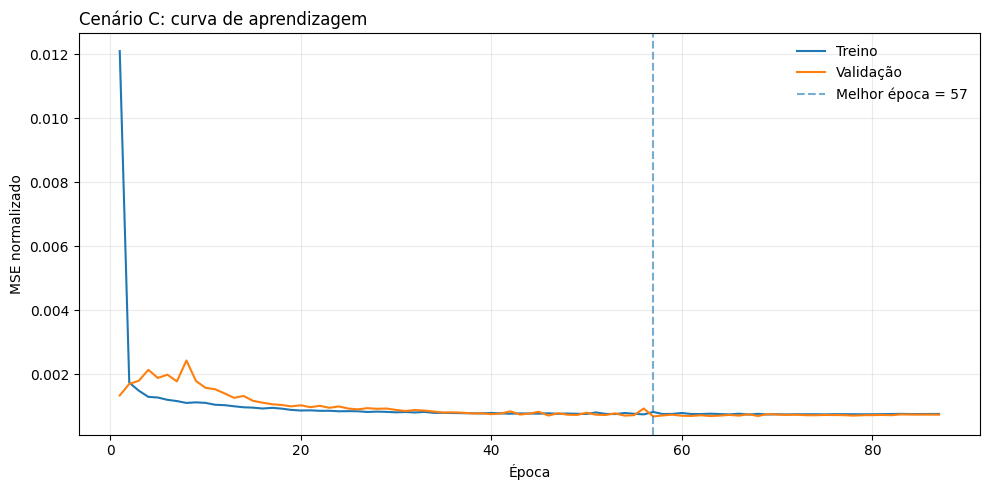

In [29]:
# ============================================================
# CÉLULA 11: CURVA DE APRENDIZAGEM
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Comparar o erro do treino e da validação ao longo das épocas.
#
# Isso permite observar:
#
#   convergência;
#   estabilidade;
#   diferença treino x validação;
#   possível overfitting;
#   posição da melhor época.
#
# A loss utilizada é o MSE sobre o alvo normalizado.
# ============================================================


# ============================================================
# 1. TRANSFORMAR HISTÓRICO EM DATAFRAME
# ============================================================

history_C_df = pd.DataFrame(
    history_C.history
)


# ============================================================
# 2. CRIAR FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 5)
)


# Loss do conjunto de treino.

ax.plot(

    history_C_df.index + 1,

    history_C_df["loss"],

    label="Treino"

)


# Loss do conjunto de validação.

ax.plot(

    history_C_df.index + 1,

    history_C_df["val_loss"],

    label="Validação"

)


# ============================================================
# 3. INDICAR A MELHOR ÉPOCA
# ============================================================

ax.axvline(

    best_epoch_C,

    linestyle="--",

    alpha=0.6,

    label=f"Melhor época = {best_epoch_C}"

)


# ============================================================
# 4. FORMATAÇÃO
# ============================================================

ax.set_title(
    "Cenário C: curva de aprendizagem",
    loc="left"
)

ax.set_xlabel(
    "Época"
)

ax.set_ylabel(
    "MSE normalizado"
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

fig.tight_layout()


# ============================================================
# 5. SALVAR FIGURA
# ============================================================

LEARNING_CURVE_PATH = (

    FIGURES

    /

    "03A01_curva_aprendizagem_C.png"

)


fig.savefig(

    LEARNING_CURVE_PATH,

    dpi=220,

    bbox_inches="tight"

)


plt.show()

### Fundamentação da avaliação de erros

MAE e RMSE pertencem às medidas usuais de magnitude do erro discutidas por Hyndman e Koehler (2006). As funções de regressão da biblioteca, incluindo R², estão documentadas no guia da biblioteca (Scikit-learn, 2025). As métricas são calculadas sobre as mesmas observações usadas na comparação indicada em cada etapa. A análise dos pares é descritiva e não equivale a um teste de significância.


In [30]:
# Referências metodológicas: (Hyndman; Koehler, 2006; Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 12: AVALIAÇÃO DO CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Aplicar o modelo treinado ao conjunto de teste e calcular:
#
#   MAE
#   RMSE
#   R²
#
#
# As previsões são produzidas inicialmente na escala
# normalizada.
#
# Antes de calcular as métricas, retornamos para a unidade
# física original:
#
#       CO₂ Mass [short tons]
# ============================================================


# ============================================================
# 1. PREVISÃO NORMALIZADA
# ============================================================

pred_C_scaled = (

    model_C

    .predict(

        X_test_C_scaled,

        verbose=0

    )

    .ravel()

)


# ============================================================
# 2. RETORNAR À ESCALA ORIGINAL
# ============================================================

pred_C = (

    scaler_y_C

    .inverse_transform(

        pred_C_scaled.reshape(
            -1,
            1
        )

    )

    .ravel()

)


# ============================================================
# 3. VALORES OBSERVADOS
# ============================================================

y_true = (

    y_test[
        TARGET
    ]

    .to_numpy()

)


# ============================================================
# 4. CALCULAR MÉTRICAS
# ============================================================

metrics_C = {


    # Erro absoluto médio.

    "MAE":

        mean_absolute_error(

            y_true,

            pred_C

        ),


    # Raiz do erro quadrático médio.

    "RMSE":

        np.sqrt(

            mean_squared_error(

                y_true,

                pred_C

            )

        ),


    # Coeficiente de determinação.

    "R2":

        r2_score(

            y_true,

            pred_C

        )

}


# ============================================================
# 5. EXIBIR RESULTADOS
# ============================================================

print("=" * 72)
print("RESULTADOS: CENÁRIO C")
print("=" * 72)


print(
    f"MAE  = {metrics_C['MAE']:.4f}"
)


print(
    f"RMSE = {metrics_C['RMSE']:.4f}"
)


print(
    f"R²   = {metrics_C['R2']:.4f}"
)

RESULTADOS: CENÁRIO C
MAE  = 62.6466
RMSE = 66.9842
R²   = 0.8910


In [31]:
# ============================================================
# CÉLULA 13: COMPARAÇÃO COM O NOTEBOOK 3A
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Colocar lado a lado:
#
# A: carga instantânea
#
# B: trajetória básica
#
# C: trajetória enriquecida
#
#
# O foco principal deste notebook é B x C.
#
# A permanece na tabela para mostrar toda a evolução do
# experimento desde o baseline inicial.
# ============================================================


# ============================================================
# 1. RECUPERAR RESULTADO DO CENÁRIO A
# ============================================================

baseline_A = (

    baseline_results[

        baseline_results["cenario"]

        .str.startswith("A")

    ]

    .iloc[0]

)


# ============================================================
# 2. RECUPERAR RESULTADO DO CENÁRIO B
# ============================================================

baseline_B = (

    baseline_results[

        baseline_results["cenario"]

        .str.startswith("B")

    ]

    .iloc[0]

)


# ============================================================
# 3. CONSTRUIR TABELA A x B x C
# ============================================================

comparison_models = pd.DataFrame([


    {

        "cenario":
            "A: carga instantânea",

        "MAE":
            baseline_A["MAE"],

        "RMSE":
            baseline_A["RMSE"],

        "R2":
            baseline_A["R2"]

    },


    {

        "cenario":
            "B: trajetória básica",

        "MAE":
            baseline_B["MAE"],

        "RMSE":
            baseline_B["RMSE"],

        "R2":
            baseline_B["R2"]

    },


    {

        "cenario":
            "C: trajetória enriquecida",

        "MAE":
            metrics_C["MAE"],

        "RMSE":
            metrics_C["RMSE"],

        "R2":
            metrics_C["R2"]

    }

])


display(
    comparison_models.round(4)
)


# ============================================================
# 4. VARIAÇÃO DE MAE ENTRE B E C
# ============================================================
#
# Resultado positivo:
# C reduziu MAE.
#
# Resultado negativo:
# C aumentou MAE.
# ============================================================

mae_gain_B_to_C = (

    100

    *

    (
        baseline_B["MAE"]
        -
        metrics_C["MAE"]
    )

    /

    baseline_B["MAE"]

)


# ============================================================
# 5. VARIAÇÃO DE RMSE ENTRE B E C
# ============================================================

rmse_gain_B_to_C = (

    100

    *

    (
        baseline_B["RMSE"]
        -
        metrics_C["RMSE"]
    )

    /

    baseline_B["RMSE"]

)


# ============================================================
# 6. VARIAÇÃO DE R²
# ============================================================
#
# Aqui utilizamos diferença absoluta, e não percentual.
# ============================================================

delta_r2_B_to_C = (

    metrics_C["R2"]

    -

    baseline_B["R2"]

)


# ============================================================
# 7. EXIBIR VARIAÇÕES
# ============================================================

print(
    f"\nRedução de MAE B → C: "
    f"{mae_gain_B_to_C:+.2f}%"
)


print(
    f"Redução de RMSE B → C: "
    f"{rmse_gain_B_to_C:+.2f}%"
)


print(
    f"Variação de R² B → C: "
    f"{delta_r2_B_to_C:+.4f}"
)

,cenario,MAE,RMSE,R2
0,A: carga instantânea,67.2508,70.9010,0.8779
1,B: trajetória básica,61.6102,67.0401,0.8908
2,C: trajetória enriquecida,62.6466,66.9842,0.8910



Redução de MAE B → C: -1.68%
Redução de RMSE B → C: +0.08%
Variação de R² B → C: +0.0002


In [32]:
# ============================================================
# CÉLULA 14: COMPARAÇÃO HORA A HORA E VIÉS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# As métricas globais não mostram em quantas observações um
# modelo efetivamente supera o outro.
#
# Nesta célula:
#
#   1. associamos B e C pela mesma hora;
#   2. comparamos os erros absolutos;
#   3. contamos quantas horas C supera B;
#   4. calculamos o viés médio dos dois modelos.
#
#
# DEFINIÇÃO DO RESÍDUO
# ------------------------------------------------------------
#
#       resíduo = observado - previsto
#
# resíduo positivo:
#       subestimação.
#
# resíduo negativo:
#       superestimação.
# ============================================================


# ============================================================
# 1. TABELA COM PREVISÕES DO CENÁRIO C
# ============================================================

current_predictions = pd.DataFrame({

    "timestamp":

        test_data[
            "timestamp"
        ]

        .to_numpy(),


    "co2_observed":

        y_true,


    "pred_C":

        pred_C

})


# ============================================================
# 2. ASSOCIAR PREVISÕES DE B E C PELO TIMESTAMP
# ============================================================
#
# inner merge garante que somente horas presentes nas duas
# tabelas sejam comparadas.
# ============================================================

comparison_predictions = (

    baseline_predictions

    .merge(

        current_predictions,

        on="timestamp",

        how="inner"

    )

)


# ============================================================
# 3. ERRO ABSOLUTO DO CENÁRIO C
# ============================================================

comparison_predictions[
    "abs_error_C"
] = (

    np.abs(

        comparison_predictions[
            "co2_observed"
        ]

        -

        comparison_predictions[
            "pred_C"
        ]

    )

)


# ============================================================
# 4. RESÍDUO DO CENÁRIO C
# ============================================================

comparison_predictions[
    "residual_C"
] = (

    comparison_predictions[
        "co2_observed"
    ]

    -

    comparison_predictions[
        "pred_C"
    ]

)


# ============================================================
# 5. CONTAR QUANTAS HORAS C TEM MENOR ERRO QUE B
# ============================================================

hours_C_better = int(

    (

        comparison_predictions[
            "abs_error_C"
        ]

        <

        comparison_predictions[
            "abs_error_B"
        ]

    )

    .sum()

)


pct_C_better = (

    100

    *

    hours_C_better

    /

    len(comparison_predictions)

)


# ============================================================
# 6. VIÉS MÉDIO
# ============================================================

bias_B = (

    comparison_predictions[
        "residual_B"
    ]

    .mean()

)


bias_C = (

    comparison_predictions[
        "residual_C"
    ]

    .mean()

)


# ============================================================
# 7. EXIBIR RESULTADOS
# ============================================================

print(
    "Horas comparadas:",
    len(comparison_predictions)
)


print(

    f"Cenário C melhor que B em "

    f"{hours_C_better} horas "

    f"({pct_C_better:.1f}%)."

)


print(

    f"\nViés médio B: "

    f"{bias_B:+.2f} short tons"

)


print(

    f"Viés médio C: "

    f"{bias_C:+.2f} short tons"

)

Horas comparadas: 1144
Cenário C melhor que B em 491 horas (42.9%).

Viés médio B: +60.89 short tons
Viés médio C: +62.13 short tons


In [33]:
# ============================================================
# CÉLULA 15: DESEMPENHO POR CONTEXTO OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se as novas features ajudam especificamente nos
# regimes que motivaram o Notebook 3A.01.
#
#
# Contextos:
#
#   1. todas as horas;
#   2. primeiras 6 horas após startup;
#   3. rampas intensas.
#
#
# Essa comparação é particularmente importante porque o
# Notebook 3A mostrou:
#
#   forte ganho de B em startups;
#
#   pior desempenho de B durante rampas intensas.
#
# Portanto, queremos descobrir se C altera esse comportamento.
# ============================================================


# ============================================================
# 1. CONSTRUIR BASE DE ANÁLISE
# ============================================================

analysis_test = (

    test_data[

        [

            "timestamp",

            "hours_since_startup",

            "abs_delta_load_1h",

            TARGET

        ]

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


# ============================================================
# 2. ADICIONAR PREVISÃO E ERRO DO CENÁRIO C
# ============================================================

analysis_test[
    "pred_C"
] = pred_C


analysis_test[
    "abs_error_C"
] = (

    np.abs(

        analysis_test[
            TARGET
        ]

        -

        analysis_test[
            "pred_C"
        ]

    )

)


# ============================================================
# 3. ASSOCIAR O ERRO DO CENÁRIO B
# ============================================================

analysis_test = (

    analysis_test

    .merge(

        baseline_predictions[

            [

                "timestamp",

                "abs_error_B"

            ]

        ],

        on="timestamp",

        how="left"

    )

)


# ============================================================
# 4. DEFINIR CONTEXTOS
# ============================================================

contexts = {


    # --------------------------------------------------------
    # Todas as observações.
    # --------------------------------------------------------

    "Todas as horas de teste":

        pd.Series(

            True,

            index=analysis_test.index

        ),


    # --------------------------------------------------------
    # Fase inicial após startup.
    # --------------------------------------------------------

    "Primeiras 6 h após startup":

        (

            (

                analysis_test[
                    "hours_since_startup"
                ]

                >=

                1

            )

            &

            (

                analysis_test[
                    "hours_since_startup"
                ]

                <=

                6

            )

        ),


    # --------------------------------------------------------
    # Rampas acima do P90 definido no conjunto de treino.
    # --------------------------------------------------------

    "Rampas intensas":

        (

            analysis_test[
                "abs_delta_load_1h"
            ]

            >=

            RAMP_THRESHOLD

        )

}


# ============================================================
# 5. CALCULAR RESULTADOS PARA CADA CONTEXTO
# ============================================================

context_rows = []


for (
    context_name,
    mask
) in contexts.items():


    subset = (

        analysis_test[
            mask
        ]

    )


    # MAE do Cenário B neste contexto.

    mae_B_context = (

        subset[
            "abs_error_B"
        ]

        .mean()

    )


    # MAE do Cenário C neste contexto.

    mae_C_context = (

        subset[
            "abs_error_C"
        ]

        .mean()

    )


    # --------------------------------------------------------
    # Percentual de melhora de B para C.
    #
    # positivo:
    #       C melhor.
    #
    # negativo:
    #       C pior.
    # --------------------------------------------------------

    improvement = (

        100

        *

        (
            mae_B_context
            -
            mae_C_context
        )

        /

        mae_B_context

    )


    context_rows.append({

        "contexto":
            context_name,

        "n":
            len(subset),

        "MAE_B":
            mae_B_context,

        "MAE_C":
            mae_C_context,

        "melhora_B_para_C_%":
            improvement

    })


# ============================================================
# 6. CONSOLIDAR
# ============================================================

context_comparison = pd.DataFrame(
    context_rows
)


display(
    context_comparison.round(3)
)

,contexto,n,MAE_B,MAE_C,melhora_B_para_C_%
0,Todas as horas de teste,1144,61.610,62.647,-1.682
1,Primeiras 6 h após startup,30,9.994,7.728,22.674
2,Rampas intensas,115,75.170,74.168,1.333


In [34]:
# ============================================================
# CÉLULA 16: DIAGNÓSTICO DE DISTRIBUIÇÃO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Investigar uma possível mudança de comportamento da unidade
# entre treino, validação e teste.
#
# O Notebook 3A apresentou tendência de subestimação.
#
# Uma hipótese possível é que a relação entre carga e emissão
# não seja exatamente igual em todos os períodos.
#
#
# Esta célula NÃO altera nem treina o modelo.
#
# É apenas uma etapa diagnóstica.
# ============================================================


# ============================================================
# 1. FUNÇÃO DE RESUMO
# ============================================================

def distribution_summary(
    data,
    label
):

    # --------------------------------------------------------
    # Para calcular CO₂/MW, excluímos cargas muito baixas.
    #
    # Dividir por valores próximos de zero produziria razões
    # extremamente elevadas e pouco informativas.
    #
    # Foi utilizado o corte de 50 MW somente para esta análise
    # diagnóstica.
    # --------------------------------------------------------

    valid_intensity = (

        data[

            data[
                "load_current_mw"
            ]

            >

            50

        ]

        .copy()

    )


    # --------------------------------------------------------
    # Indicador simples de intensidade:
    #
    #       CO₂ horário / carga atual
    #
    # Não é utilizado como feature do modelo.
    # --------------------------------------------------------

    valid_intensity[
        "co2_per_mw"
    ] = (

        valid_intensity[
            TARGET
        ]

        /

        valid_intensity[
            "load_current_mw"
        ]

    )


    # --------------------------------------------------------
    # Retornar estatísticas de cada período.
    # --------------------------------------------------------

    return {

        "conjunto":
            label,

        "n":
            len(data),

        "carga_media_mw":

            data[
                "load_current_mw"
            ]

            .mean(),

        "carga_mediana_mw":

            data[
                "load_current_mw"
            ]

            .median(),

        "co2_medio":

            data[
                TARGET
            ]

            .mean(),

        "co2_mediano":

            data[
                TARGET
            ]

            .median(),

        "intensidade_mediana_co2_por_mw":

            valid_intensity[
                "co2_per_mw"
            ]

            .median()

    }


# ============================================================
# 2. COMPARAR TREINO, VALIDAÇÃO E TESTE
# ============================================================

distribution_table = pd.DataFrame([


    distribution_summary(
        train_data,
        "Treino"
    ),


    distribution_summary(
        validation_data,
        "Validação"
    ),


    distribution_summary(
        test_data,
        "Teste"
    )

])


display(
    distribution_table.round(4)
)

,conjunto,n,carga_media_mw,carga_mediana_mw,co2_medio,co2_mediano,intensidade_mediana_co2_por_mw
0,Treino,4894,665.5541,691.5,581.0168,594.35,0.8860
1,Validação,211,681.3270,855.0,553.5576,651.30,0.7996
2,Teste,1144,666.7404,672.5,588.5415,598.80,0.8837


### Célula 17: diagnóstico descritivo de *distribution shift* e risco de extrapolação

Aqui, **distribution shift** significa investigar se a distribuição das variáveis de entrada do teste difere da observada no treinamento. A célula calcula, para cada *feature*, as médias em treino e teste e a porcentagem de observações de teste que ficam fora do intervalo `[mínimo de treino, máximo de treino]`.

O segundo indicador é particularmente útil para avaliar o **risco de extrapolação (*extrapolation risk*)**, já que parte das entradas pode assumir valores não representados no treinamento. Contudo, valores fora do intervalo são apenas um **sinal descritivo de possível deslocamento e necessidade de extrapolação**. A comparação de médias, isoladamente, também não equivale a uma caracterização completa das distribuições.

**Limite inferencial:** este procedimento **não realiza um teste estatístico formal de *covariate shift*** e não determina se a relação condicional entre emissão e variáveis operacionais mudou. Portanto, não é adequado escrever que *covariate shift* ou *concept drift* foi comprovado. O resultado sustenta apenas um **diagnóstico exploratório de diferenças entre períodos e possível risco de extrapolação**.

### Alcance do diagnóstico de distribuição

A literatura distingue mudanças de distribuição e adaptação a concept drift (Gama *et al.*, 2014). Os indicadores desta etapa descrevem diferenças entre períodos e risco de extrapolação. Eles não constituem um detector formal de concept drift nem demonstram alteração causal do mecanismo físico que relaciona carga e emissão.


In [35]:
# Referências metodológicas: (Gama et al., 2014).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
#
# FUNDAMENTAÇÃO METODOLÓGICA: DISTRIBUTION SHIFT
# Diagnóstico DESCRITIVO de mudanças nas features e extrapolation risk.
# Médias e % fora da faixa do treino não provam covariate shift nem
# concept drift e não equivalem a teste formal dessas hipóteses.
#
# CÉLULA 17: DIAGNÓSTICO DE SHIFT DAS FEATURES
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se o conjunto de teste contém valores de entrada
# fora do intervalo observado durante o treinamento.
#
#
# POR QUE ISSO IMPORTA?
# ------------------------------------------------------------
# Redes neurais normalmente generalizam melhor dentro de regiões
# semelhantes às apresentadas durante o treinamento.
#
# Se uma feature assume no teste valores nunca observados no
# treino, o modelo precisa extrapolar.
#
#
# Para cada variável calculamos:
#
#   média no treino;
#   média no teste;
#   percentual do teste fora do intervalo [mínimo, máximo]
#   observado no treino.
#
#
# Esta análise é somente diagnóstica.
# ============================================================


# ============================================================
# 1. LISTA PARA ARMAZENAR RESULTADOS
# ============================================================

feature_shift_rows = []


# ============================================================
# 2. ANALISAR CADA FEATURE
# ============================================================

for feature in FEATURES_C:


    # --------------------------------------------------------
    # Limites aprendidos a partir do treino.
    # --------------------------------------------------------

    train_min = (

        train_data[
            feature
        ]

        .min()

    )


    train_max = (

        train_data[
            feature
        ]

        .max()

    )


    # --------------------------------------------------------
    # Valores presentes no teste.
    # --------------------------------------------------------

    test_values = (

        test_data[
            feature
        ]

    )


    # --------------------------------------------------------
    # Identificar observações que estão abaixo do mínimo ou
    # acima do máximo visto no treino.
    # --------------------------------------------------------

    outside = (

        (

            test_values

            <

            train_min

        )

        |

        (

            test_values

            >

            train_max

        )

    )


    # --------------------------------------------------------
    # Armazenar estatísticas.
    # --------------------------------------------------------

    feature_shift_rows.append({

        "feature":
            feature,

        "train_mean":

            train_data[
                feature
            ]

            .mean(),

        "test_mean":

            test_data[
                feature
            ]

            .mean(),

        "test_outside_train_range_pct":

            100

            *

            outside.mean()

    })


# ============================================================
# 3. CONSTRUIR TABELA
# ============================================================

feature_shift = pd.DataFrame(
    feature_shift_rows
)


# ============================================================
# 4. ORDENAR PELAS FEATURES COM MAIOR EXTRAPOLAÇÃO
# ============================================================

feature_shift = (

    feature_shift

    .sort_values(

        "test_outside_train_range_pct",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 5. MOSTRAR AS 15 MAIS RELEVANTES
# ============================================================

display(

    feature_shift

    .head(15)

    .round(3)

)

,feature,train_mean,test_mean,test_outside_train_range_pct
0,hours_since_startup,157.611,166.281,1.486
1,abs_delta_load_1h,38.138,37.074,0.087
2,delta_load_1h,1.292,0.389,0.087
3,delta_load_lag_1h,2.796,1.870,0.087
4,load_acceleration_1h,-1.504,-1.481,0.087
5,ramp_down_mw,18.423,18.343,0.087
6,load_current_mw,665.554,666.740,0.000
7,load_lag_1h,664.262,666.351,0.000
8,load_lag_2h,661.465,664.482,0.000
9,operating_time_lag_1h,0.991,0.995,0.000


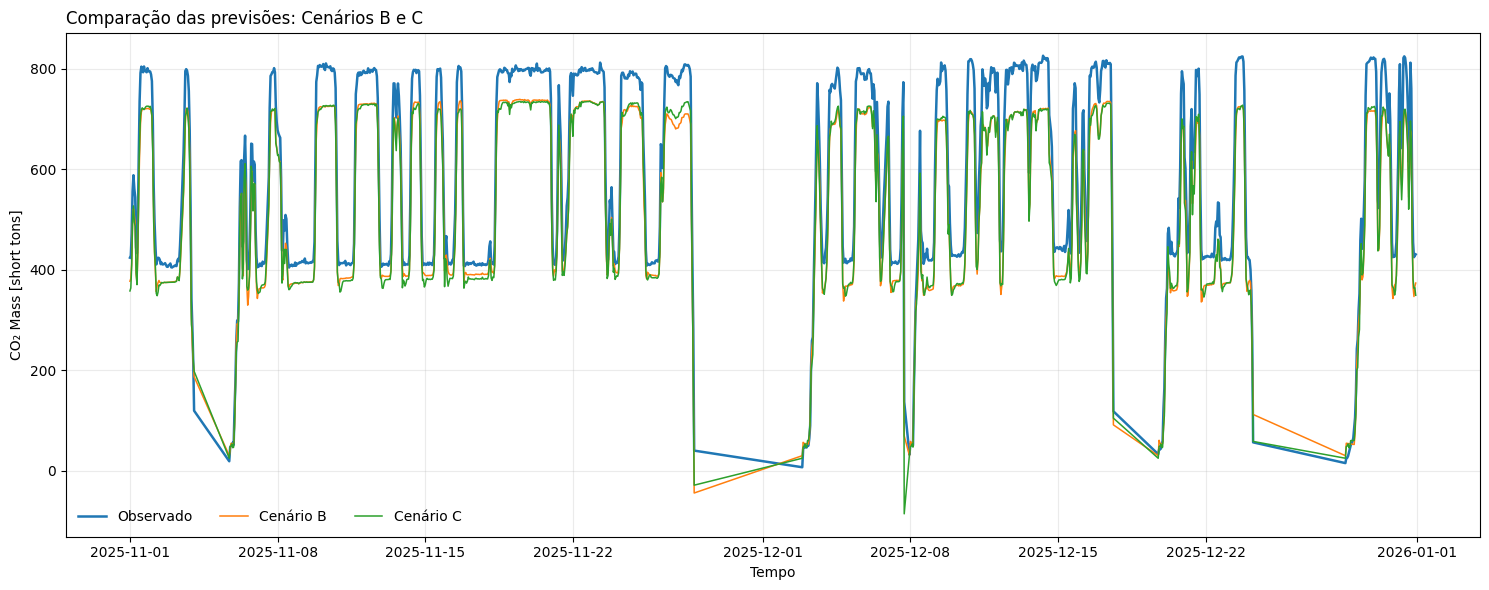

In [36]:
# ============================================================
# CÉLULA 18: OBSERVADO x CENÁRIO B x CENÁRIO C
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Comparar visualmente:
#
#   emissão observada;
#   previsão do Cenário B;
#   previsão do Cenário C.
#
#
# A tabela de métricas informa qual modelo tem menor erro médio.
#
# O gráfico permite observar em quais períodos as diferenças
# aparecem e se existe tendência visual de subestimação ou
# superestimação.
# ============================================================


# ============================================================
# 1. CRIAR FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 6)
)


# Série observada.

ax.plot(

    comparison_predictions[
        "timestamp"
    ],

    comparison_predictions[
        "co2_observed"
    ],

    label="Observado",

    linewidth=1.8

)


# Cenário B.

ax.plot(

    comparison_predictions[
        "timestamp"
    ],

    comparison_predictions[
        "co2_pred_B_short_tons"
    ],

    label="Cenário B",

    linewidth=1.1

)


# Cenário C.

ax.plot(

    comparison_predictions[
        "timestamp"
    ],

    comparison_predictions[
        "pred_C"
    ],

    label="Cenário C",

    linewidth=1.1

)


# ============================================================
# 2. FORMATAÇÃO
# ============================================================

ax.set_title(
    "Comparação das previsões: Cenários B e C",
    loc="left"
)

ax.set_xlabel(
    "Tempo"
)

ax.set_ylabel(
    "CO₂ Mass [short tons]"
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False,
    ncol=3
)

fig.tight_layout()


# ============================================================
# 3. SALVAR FIGURA
# ============================================================

FIGURE_PATH = (

    FIGURES

    /

    "03A01_observado_B_C.png"

)


fig.savefig(

    FIGURE_PATH,

    dpi=220,

    bbox_inches="tight"

)


plt.show()

In [37]:
# ============================================================
# CÉLULA 19: PERSISTÊNCIA DOS RESULTADOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Salvar todos os artefatos necessários para:
#
#   reproduzir a análise;
#   consultar os resultados posteriormente;
#   comparar com experimentos futuros;
#   carregar o modelo sem novo treinamento.
#
#
# São persistidos:
#
#   tabelas;
#   previsões;
#   diagnóstico de shift;
#   modelo neural;
#   scalers.
# ============================================================


# ============================================================
# 1. CAMINHOS DAS TABELAS
# ============================================================

COMPARISON_PATH = (

    TABLES

    /

    "03A01_comparacao_modelos.csv"

)


CONTEXT_PATH = (

    TABLES

    /

    "03A01_comparacao_contextos.csv"

)


SHIFT_PATH = (

    TABLES

    /

    "03A01_feature_shift.csv"

)


PREDICTIONS_PATH = (

    TABLES

    /

    "03A01_previsoes_C.csv"

)


# ============================================================
# 2. CAMINHO DO MODELO
# ============================================================

MODEL_C_PATH = (

    MODELS

    /

    "03A01_mlp_cenario_C.keras"

)


# ============================================================
# 3. SALVAR TABELAS
# ============================================================

comparison_models.to_csv(
    COMPARISON_PATH,
    index=False
)


context_comparison.to_csv(
    CONTEXT_PATH,
    index=False
)


feature_shift.to_csv(
    SHIFT_PATH,
    index=False
)


comparison_predictions.to_csv(
    PREDICTIONS_PATH,
    index=False
)


# ============================================================
# 4. SALVAR REDE NEURAL
# ============================================================

model_C.save(
    MODEL_C_PATH
)


# ============================================================
# 5. SALVAR SCALERS
# ============================================================
#
# O scaler de X é necessário para preparar novos dados usando
# exatamente a mesma escala do treinamento.
#
# O scaler de y permite transformar previsões normalizadas para
# short tons.
# ============================================================

joblib.dump(

    scaler_X_C,

    MODELS
    /
    "03A01_scaler_X_C.joblib"

)


joblib.dump(

    scaler_y_C,

    MODELS
    /
    "03A01_scaler_y_C.joblib"

)


# ============================================================
# 6. CONFIRMAÇÃO
# ============================================================

print(
    "Artefatos salvos."
)

Artefatos salvos.


### Célula 20: fundamentação metodológica e interpretação dos resultados

O relatório `relatorio_modelagem_preditiva_03A01.md` reúne os resultados do experimento e a descrição das técnicas utilizadas em cada etapa, desde a construção das variáveis temporais até a avaliação da MLP.

As conclusões devem considerar a comparação B versus C, a utilização de um período de teste já empregado no Notebook 3A e o caráter descritivo do diagnóstico de distribuição das variáveis. Esses fatores delimitam a força das inferências sobre a capacidade de generalização temporal.


In [38]:
# ============================================================
# CÉLULA 20: RELATÓRIO E DIAGNÓSTICO DO NOTEBOOK 3A.01
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Consolidar os resultados do experimento e gerar uma
# interpretação automática baseada nas métricas calculadas.
#
#
# O diagnóstico responde principalmente a duas perguntas:
#
# 1. O Cenário C melhorou globalmente em relação ao B?
#
# 2. O Cenário C corrigiu o problema observado anteriormente
#    durante rampas intensas?
#
#
# IMPORTANTE
# ------------------------------------------------------------
# A interpretação é gerada a partir dos resultados observados.
#
# O código não força uma conclusão favorável ao Cenário C.
# ============================================================


# ============================================================
# 1. RECUPERAR RESULTADO DO CONTEXTO DE STARTUP
# ============================================================

startup_result = (

    context_comparison[

        context_comparison[
            "contexto"
        ]

        ==

        "Primeiras 6 h após startup"

    ]

    .iloc[0]

)


# ============================================================
# 2. RECUPERAR RESULTADO DAS RAMPAS INTENSAS
# ============================================================

ramp_result = (

    context_comparison[

        context_comparison[
            "contexto"
        ]

        ==

        "Rampas intensas"

    ]

    .iloc[0]

)


# ============================================================
# 3. DIAGNÓSTICO GLOBAL
# ============================================================
#
# Para declarar melhora consistente, exigimos simultaneamente:
#
#       MAE_C  < MAE_B
#       RMSE_C < RMSE_B
#       R²_C   > R²_B
#
# Portanto, uma melhora isolada em apenas uma métrica não é
# classificada automaticamente como superioridade global.
# ============================================================

if (

    metrics_C["MAE"]
    <
    baseline_B["MAE"]

    and

    metrics_C["RMSE"]
    <
    baseline_B["RMSE"]

    and

    metrics_C["R2"]
    >
    baseline_B["R2"]

):

    global_diagnosis = """
O Cenário C apresentou melhora consistente nas três métricas
globais em relação ao Cenário B.

Isso indica que o enriquecimento da representação temporal
adicionou informação útil ao modelo.
"""


else:

    global_diagnosis = """
O Cenário C não apresentou melhora consistente nas três métricas
globais em relação ao Cenário B.

Isso sugere que simplesmente acrescentar mais informações de
trajetória não é suficiente para melhorar a capacidade de
generalização da MLP atual.
"""


# ============================================================
# 4. DIAGNÓSTICO ESPECÍFICO DAS RAMPAS
# ============================================================
#
# melhora_B_para_C_% > 0:
#
#       C reduziu MAE nas rampas.
#
# melhora_B_para_C_% < 0:
#
#       C aumentou MAE nas rampas.
# ============================================================

if (

    ramp_result[
        "melhora_B_para_C_%"
    ]

    >

    0

):

    ramp_diagnosis = """
O Cenário C também reduziu o erro durante rampas intensas.

Esse resultado é particularmente relevante porque as rampas
constituíam a principal deficiência identificada no Notebook 3A.
"""


else:

    ramp_diagnosis = """
As rampas intensas continuam sendo um regime problemático.

Mesmo com uma representação temporal mais extensa, o erro não
foi reduzido nesse subconjunto.

Isso sugere que o próximo passo poderá exigir mudança na função
de perda, ponderação por regime, otimização da arquitetura ou
uma família de modelos diferente.
"""


# ============================================================
# 5. CONSTRUIR RELATÓRIO AUTOMÁTICO
# ============================================================
#
# Os valores utilizados abaixo vêm diretamente das variáveis
# calculadas pelo notebook.
#
# Isso evita transcrição manual dos resultados.
# ============================================================

report_03A01 = f"""
# Relatório: Notebook 3A.01

## 1. Objetivo

Avaliar se uma representação temporal mais completa da
trajetória operacional melhora a estimação horária de CO₂ em
relação ao Cenário B do Notebook 3A.

## 2. Controle experimental

Foram mantidos:

- mesma arquitetura MLP;
- mesmo otimizador Adam;
- mesma função de perda MSE;
- mesmo learning rate;
- mesmo batch size;
- mesma divisão temporal;
- mesma estratégia de EarlyStopping.

A principal modificação foi o conjunto de features.

## 3. Resultados

### Cenário B

- MAE: **{baseline_B['MAE']:.4f}**
- RMSE: **{baseline_B['RMSE']:.4f}**
- R²: **{baseline_B['R2']:.4f}**

### Cenário C

- MAE: **{metrics_C['MAE']:.4f}**
- RMSE: **{metrics_C['RMSE']:.4f}**
- R²: **{metrics_C['R2']:.4f}**

### Variação B → C

- redução de MAE: **{mae_gain_B_to_C:+.2f}%**
- redução de RMSE: **{rmse_gain_B_to_C:+.2f}%**
- variação de R²: **{delta_r2_B_to_C:+.4f}**

## 4. Comparação hora a hora

O Cenário C apresentou erro inferior ao Cenário B em:

**{hours_C_better} de {len(comparison_predictions)} horas**

ou:

**{pct_C_better:.1f}% das observações.**

## 5. Viés

- viés médio B: **{bias_B:+.2f} short tons**
- viés médio C: **{bias_C:+.2f} short tons**

## 6. Startup

Melhora B → C nas primeiras 6 horas após startup:

**{startup_result['melhora_B_para_C_%']:+.2f}%**

## 7. Rampas intensas

Limiar:

**|ΔP| ≥ {RAMP_THRESHOLD:.2f} MW/h**

Melhora B → C:

**{ramp_result['melhora_B_para_C_%']:+.2f}%**

## 8. Diagnóstico global

{global_diagnosis}

## 9. Diagnóstico das rampas

{ramp_diagnosis}

## 10. Próxima decisão metodológica

O resultado deste notebook deverá determinar o próximo
experimento.

Se o enriquecimento temporal produzir ganho consistente,
a próxima etapa poderá investigar:

- otimização de hiperparâmetros;
- Huber Loss;
- validação temporal progressiva.

Se o ganho for pequeno ou inexistente, deverá ser considerada
a comparação com outra família de modelos, como gradient
boosting.

Se as métricas globais melhorarem, mas as rampas continuarem
problemáticas, poderá ser testada uma estratégia orientada a
regimes, incluindo ponderação de erros ou modelos especializados.

Nenhuma dessas alternativas será aplicada automaticamente antes
da análise dos resultados obtidos neste notebook.


## 11. Fundamentação metodológica das técnicas de modelagem e avaliação

### 11.1. Aprendizado supervisionado, regressão e arquitetura da IA

O problema é formulado como **supervised regression**, com CO₂ horário como variável-alvo contínua. O Cenário C utiliza uma **Multilayer Perceptron (MLP)**, uma rede neural artificial do tipo **feedforward** com camadas densas, ReLU nas camadas ocultas e saída linear. O treinamento é realizado por **backpropagation**, calculada internamente pelo TensorFlow/Keras, e os pesos são ajustados pelo **otimizador Adam**, com **MSE** como função de perda. Não se trata de uma rede neural recorrente: a memória do processo é fornecida pelas features temporais construídas explicitamente.

### 11.2. Engenharia de variáveis temporais (temporal feature engineering)

- **Lagged features**: `shift(n)` cria defasagens observacionais de carga e de rampas, incluindo `P(t−2)`, `P(t−3)` e `P(t−6)`.
- **Rolling-window features**: `shift(1).rolling(...)` seguido de média, desvio padrão, mínimo e máximo resume janelas de observações anteriores à hora atual.
- **Look-ahead bias prevention**: aplicar `shift(1)` antes de `rolling(...)` impede que a própria hora `t` integre estatísticas destinadas a descrever apenas o histórico; essa é uma medida de prevenção de **temporal data leakage**.
- **Representação temporal operacional**: histórico ON/OFF, fase após startup, aceleração e direção das rampas descrevem regimes de operação.
- **Ressalva**: `shift(n)` representa `n` linhas e só pode ser interpretado como `n` horas quando a frequência temporal estiver efetivamente regular.

A carga da própria hora `P(t)` permanece como entrada. Assim, o experimento é de **estimação contemporânea de CO₂** e não demonstra capacidade de previsão antecipada a partir de dados exclusivamente anteriores à hora prevista.

### 11.3. Comparação controlada dos conjuntos de features

O estudo de B para C é uma **controlled feature-set comparison**, com lógica de **ablação incremental**: acrescentam-se variáveis temporais mantendo a arquitetura geral da MLP, os principais parâmetros de treinamento e a divisão cronológica. Como o Cenário B provém do Notebook 3A, a interpretação de diferenças deve considerar eventuais diferenças na amostra efetivamente elegível entre os experimentos; não se pressupõe pareamento completo sem verificação explícita.

### 11.4. Protocolo temporal e prevenção de vazamento

A separação cronológica do conjunto de dados é um **temporal holdout**: janeiro a setembro para treinamento, outubro para validação, novembro e dezembro para teste. A normalização Min-Max é ajustada somente ao treino e depois aplicada à validação e ao teste. O limiar de rampas intensas (P90) também é estimado exclusivamente no treino. Esses controles reduzem riscos de **data leakage**. Como o período de teste já foi examinado em trabalhos anteriores, futuras decisões de desenvolvimento não devem tratá-lo como teste inteiramente cego.

### 11.5. Distribution shift e risco de extrapolação

A comparação das médias das features entre treino e teste, juntamente com a proporção de valores do teste fora dos limites mínimo e máximo de treinamento, constitui um **diagnóstico descritivo de distribution shift e extrapolation risk**. Esse procedimento não é um teste formal de **covariate shift** ou **concept drift** e não comprova alteração na relação entre variáveis operacionais e emissões. Conclusões mais fortes exigiriam procedimentos específicos adicionais.

### 11.6. Síntese das técnicas empregadas

| Técnica | Aplicação no Notebook 3A.01 | Limite de interpretação |
|---|---|---|
| Supervised regression / MLP feedforward | Estima CO₂ a partir das features operacionais | Não constitui RNN nem previsão antecipada obrigatoriamente |
| Temporal feature engineering | Constrói memória operacional explícita | Exige coerência da ordenação temporal |
| Lagged features | `shift(n)` | Linhas não equivalem necessariamente a horas se houver lacunas |
| Rolling-window features | `shift(1).rolling(...)` | As estatísticas descrevem somente períodos passados |
| Look-ahead bias prevention | `shift(1)` nas janelas históricas | Não elimina automaticamente todas as possibilidades de leakage |
| Temporal holdout | Treino, validação e teste cronológicos | Teste já conhecido dos experimentos anteriores |
| Controlled feature-set comparison | Comparação B versus C mantendo arquitetura | A equivalência de amostras deve ser avaliada |
| Distribution shift (descritivo) | Médias e limites das features no teste | Não prova covariate shift nem concept drift |

A interpretação dos resultados deve considerar que o experimento avalia a estimação contemporânea das emissões, que o período de teste foi reutilizado após o Notebook 3A e que o diagnóstico de alterações na distribuição das entradas é descritivo, não uma comprovação formal de *covariate shift* ou *concept drift*.
"""


# ============================================================
# 6. EXIBIR RELATÓRIO NO COLAB
# ============================================================

display(
    Markdown(
        report_03A01
    )
)


# ============================================================
# 7. SALVAR RELATÓRIO
# ============================================================

REPORT_PATH = (

    REPORTS

    /

    "relatorio_modelagem_preditiva_03A01.md"

)


with open(

    REPORT_PATH,

    "w",

    encoding="utf-8"

) as f:

    f.write(
        report_03A01
    )


# ============================================================
# 8. CONFIRMAÇÃO
# ============================================================

print(
    "\nRelatório salvo em:"
)

print(
    REPORT_PATH
)


# Relatório: Notebook 3A.01

## 1. Objetivo

Avaliar se uma representação temporal mais completa da
trajetória operacional melhora a estimação horária de CO₂ em
relação ao Cenário B do Notebook 3A.

## 2. Controle experimental

Foram mantidos:

- mesma arquitetura MLP;
- mesmo otimizador Adam;
- mesma função de perda MSE;
- mesmo learning rate;
- mesmo batch size;
- mesma divisão temporal;
- mesma estratégia de EarlyStopping.

A principal modificação foi o conjunto de features.

## 3. Resultados

### Cenário B

- MAE: **61.6102**
- RMSE: **67.0401**
- R²: **0.8908**

### Cenário C

- MAE: **62.6466**
- RMSE: **66.9842**
- R²: **0.8910**

### Variação B → C

- redução de MAE: **-1.68%**
- redução de RMSE: **+0.08%**
- variação de R²: **+0.0002**

## 4. Comparação hora a hora

O Cenário C apresentou erro inferior ao Cenário B em:

**491 de 1144 horas**

ou:

**42.9% das observações.**

## 5. Viés

- viés médio B: **+60.89 short tons**
- viés médio C: **+62.13 short tons**

## 6. Startup

Melhora B → C nas primeiras 6 horas após startup:

**+22.67%**

## 7. Rampas intensas

Limiar:

**|ΔP| ≥ 130.00 MW/h**

Melhora B → C:

**+1.33%**

## 8. Diagnóstico global


O Cenário C não apresentou melhora consistente nas três métricas
globais em relação ao Cenário B.

Isso sugere que simplesmente acrescentar mais informações de
trajetória não é suficiente para melhorar a capacidade de
generalização da MLP atual.


## 9. Diagnóstico das rampas


O Cenário C também reduziu o erro durante rampas intensas.

Esse resultado é particularmente relevante porque as rampas
constituíam a principal deficiência identificada no Notebook 3A.


## 10. Próxima decisão metodológica

O resultado deste notebook deverá determinar o próximo
experimento.

Se o enriquecimento temporal produzir ganho consistente,
a próxima etapa poderá investigar:

- otimização de hiperparâmetros;
- Huber Loss;
- validação temporal progressiva.

Se o ganho for pequeno ou inexistente, deverá ser considerada
a comparação com outra família de modelos, como gradient
boosting.

Se as métricas globais melhorarem, mas as rampas continuarem
problemáticas, poderá ser testada uma estratégia orientada a
regimes, incluindo ponderação de erros ou modelos especializados.

Nenhuma dessas alternativas será aplicada automaticamente antes
da análise dos resultados obtidos neste notebook.


## 11. Fundamentação metodológica das técnicas de modelagem e avaliação

### 11.1. Aprendizado supervisionado, regressão e arquitetura da IA

O problema é formulado como **supervised regression**, com CO₂ horário como variável-alvo contínua. O Cenário C utiliza uma **Multilayer Perceptron (MLP)**, uma rede neural artificial do tipo **feedforward** com camadas densas, ReLU nas camadas ocultas e saída linear. O treinamento é realizado por **backpropagation**, calculada internamente pelo TensorFlow/Keras, e os pesos são ajustados pelo **otimizador Adam**, com **MSE** como função de perda. Não se trata de uma rede neural recorrente: a memória do processo é fornecida pelas features temporais construídas explicitamente.

### 11.2. Engenharia de variáveis temporais (temporal feature engineering)

- **Lagged features**: `shift(n)` cria defasagens observacionais de carga e de rampas, incluindo `P(t−2)`, `P(t−3)` e `P(t−6)`.
- **Rolling-window features**: `shift(1).rolling(...)` seguido de média, desvio padrão, mínimo e máximo resume janelas de observações anteriores à hora atual.
- **Look-ahead bias prevention**: aplicar `shift(1)` antes de `rolling(...)` impede que a própria hora `t` integre estatísticas destinadas a descrever apenas o histórico; essa é uma medida de prevenção de **temporal data leakage**.
- **Representação temporal operacional**: histórico ON/OFF, fase após startup, aceleração e direção das rampas descrevem regimes de operação.
- **Ressalva**: `shift(n)` representa `n` linhas e só pode ser interpretado como `n` horas quando a frequência temporal estiver efetivamente regular.

A carga da própria hora `P(t)` permanece como entrada. Assim, o experimento é de **estimação contemporânea de CO₂** e não demonstra capacidade de previsão antecipada a partir de dados exclusivamente anteriores à hora prevista.

### 11.3. Comparação controlada dos conjuntos de features

O estudo de B para C é uma **controlled feature-set comparison**, com lógica de **ablação incremental**: acrescentam-se variáveis temporais mantendo a arquitetura geral da MLP, os principais parâmetros de treinamento e a divisão cronológica. Como o Cenário B provém do Notebook 3A, a interpretação de diferenças deve considerar eventuais diferenças na amostra efetivamente elegível entre os experimentos; não se pressupõe pareamento completo sem verificação explícita.

### 11.4. Protocolo temporal e prevenção de vazamento

A separação cronológica do conjunto de dados é um **temporal holdout**: janeiro a setembro para treinamento, outubro para validação, novembro e dezembro para teste. A normalização Min-Max é ajustada somente ao treino e depois aplicada à validação e ao teste. O limiar de rampas intensas (P90) também é estimado exclusivamente no treino. Esses controles reduzem riscos de **data leakage**. Como o período de teste já foi examinado em trabalhos anteriores, futuras decisões de desenvolvimento não devem tratá-lo como teste inteiramente cego.

### 11.5. Distribution shift e risco de extrapolação

A comparação das médias das features entre treino e teste, juntamente com a proporção de valores do teste fora dos limites mínimo e máximo de treinamento, constitui um **diagnóstico descritivo de distribution shift e extrapolation risk**. Esse procedimento não é um teste formal de **covariate shift** ou **concept drift** e não comprova alteração na relação entre variáveis operacionais e emissões. Conclusões mais fortes exigiriam procedimentos específicos adicionais.

### 11.6. Síntese das técnicas empregadas

| Técnica | Aplicação no Notebook 3A.01 | Limite de interpretação |
|---|---|---|
| Supervised regression / MLP feedforward | Estima CO₂ a partir das features operacionais | Não constitui RNN nem previsão antecipada obrigatoriamente |
| Temporal feature engineering | Constrói memória operacional explícita | Exige coerência da ordenação temporal |
| Lagged features | `shift(n)` | Linhas não equivalem necessariamente a horas se houver lacunas |
| Rolling-window features | `shift(1).rolling(...)` | As estatísticas descrevem somente períodos passados |
| Look-ahead bias prevention | `shift(1)` nas janelas históricas | Não elimina automaticamente todas as possibilidades de leakage |
| Temporal holdout | Treino, validação e teste cronológicos | Teste já conhecido dos experimentos anteriores |
| Controlled feature-set comparison | Comparação B versus C mantendo arquitetura | A equivalência de amostras deve ser avaliada |
| Distribution shift (descritivo) | Médias e limites das features no teste | Não prova covariate shift nem concept drift |

A interpretação dos resultados deve considerar que o experimento avalia a estimação contemporânea das emissões, que o período de teste foi reutilizado após o Notebook 3A e que o diagnóstico de alterações na distribuição das entradas é descritivo, não uma comprovação formal de *covariate shift* ou *concept drift*.



Relatório salvo em:
/content/drive/MyDrive/co2-cems-thermal-modeling/outputs/reports/relatorio_modelagem_preditiva_03A01.md


## Referências

CAWLEY, G. C.; TALBOT, N. L. C. On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation. **Journal of Machine Learning Research**, *[s. l.]*, v. 11, n. 70, p. 2079-2107, 2010. Disponível em: https://jmlr.org/papers/v11/cawley10a.html. Acesso em: 24 out. 2026.

CERQUEIRA, V.; TORGO, L.; MOZETIČ, I. Evaluating time series forecasting models: an empirical study on performance estimation methods. **Machine Learning**, *[s. l.]*, v. 109, n. 11, p. 1997-2028, 2020. DOI: https://doi.org/10.1007/s10994-020-05910-7. Disponível em: https://link.springer.com/article/10.1007/s10994-020-05910-7. Acesso em: 24 out. 2026.

GAMA, J.; ŽLIOBAITĖ, I.; BIFET, A.; PECHENIZKIY, M.; BOUCHACHIA, A. A survey on concept drift adaptation. **ACM Computing Surveys**, *[s. l.]*, v. 46, n. 4, art. 44, p. 1-37, 2014. DOI: https://doi.org/10.1145/2523813. Disponível em: https://dl.acm.org/doi/10.1145/2523813. Acesso em: 24 out. 2026.

GLOROT, X.; BORDES, A.; BENGIO, Y. Deep Sparse Rectifier Neural Networks. *In:* INTERNATIONAL CONFERENCE ON ARTIFICIAL INTELLIGENCE AND STATISTICS, 14., 2011, Fort Lauderdale. **Proceedings [...]**. *[S. l.]*: PMLR, 2011. v. 15, p. 315-323. Disponível em: https://proceedings.mlr.press/v15/glorot11a.html. Acesso em: 24 out. 2026.

HYNDMAN, R. J.; KOEHLER, A. B. Another look at measures of forecast accuracy. **International Journal of Forecasting**, *[s. l.]*, v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001. Disponível em: https://robjhyndman.com/publications/another-look-at-measures-of-forecast-accuracy/. Acesso em: 24 out. 2026.

KINGMA, D. P.; BA, J. **Adam**: A Method for Stochastic Optimization. *[S. l.: s. n.]*, 2015. Trabalho apresentado na 3rd International Conference on Learning Representations, San Diego, 2015. Disponível em: https://arxiv.org/abs/1412.6980. Acesso em: 24 out. 2026.


RUMELHART, D. E.; HINTON, G. E.; WILLIAMS, R. J. Learning representations by back-propagating errors. **Nature**, *[s. l.]*, v. 323, n. 6088, p. 533-536, 1986. DOI: https://doi.org/10.1038/323533a0. Disponível em: https://www.cs.toronto.edu/~hinton/absps/naturebp.pdf. Acesso em: 24 out. 2026.

SCIKIT-LEARN. **User Guide**. Version 1.8.0. *[S. l.]*: The scikit-learn developers, [2025]. Disponível em: https://scikit-learn.org/1.8/user_guide.html. Acesso em: 24 out. 2026.

GU, J.; SWARD, J. A.; ZHANG, K. M. Predicting power plant emissions using public data and machine learning. **Environmental Science: Advances**, *[s. l.]*, v. 2, p. 1696-1707, 2023. DOI: https://doi.org/10.1039/D3VA00191A. Disponível em: https://pubs.rsc.org/en/content/articlehtml/2023/va/d3va00191a. Acesso em: 29 out. 2026.

SURI, D.; DE CHALENDAR, J.; AZEVEDO, I. M. L. Assessing the real implications for CO₂ as generation from renewables increases. **Nature Communications**, *[s. l.]*, v. 16, art. 7124, 2025. DOI: https://doi.org/10.1038/s41467-025-59800-4. Disponível em: https://www.nature.com/articles/s41467-025-59800-4. Acesso em: 29 out. 2026.
